In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Using device: cuda
GPU: Tesla T4


In [4]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=train_transform)
test_dataset  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = torch.utils.data.DataLoader(test_dataset,  batch_size=128, shuffle=False, num_workers=2)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
CLASS_EMOJI = ['✈️', '🚗', '🐦', '🐱', '🦌', '🐶', '🐸', '🐴', '🚢', '🚚']

print(f'Training images : {len(train_dataset):,}')
print(f'Test images     : {len(test_dataset):,}')

  0%|          | 819k/170M [00:08<28:12, 100kB/s]


KeyboardInterrupt: 

NameError: name 'train_dataset' is not defined

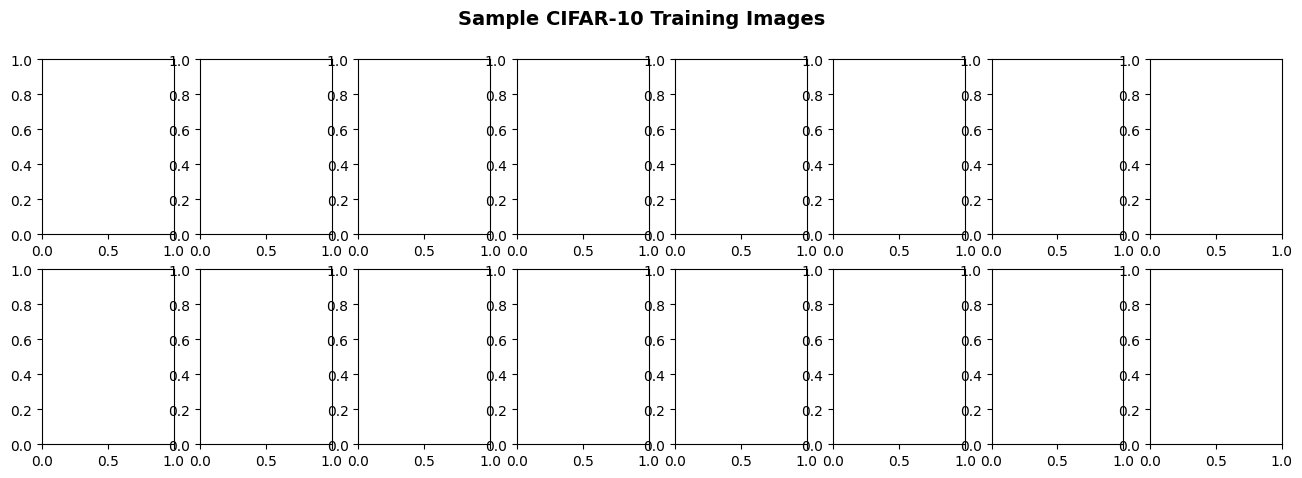

In [3]:
def denormalize(tensor):
    mean = torch.tensor(CIFAR10_MEAN).view(3,1,1)
    std  = torch.tensor(CIFAR10_STD).view(3,1,1)
    return (tensor * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle('Sample CIFAR-10 Training Images', fontsize=14, fontweight='bold')
indices = np.random.choice(len(train_dataset), 16, replace=False)
for ax, idx in zip(axes.flat, indices):
    img, label = train_dataset[idx]
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(f'{CLASS_EMOJI[label]} {CLASS_NAMES[label]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [1]:
# ResNet for CIFAR-10
#
# Paper section mapping:
# BasicBlock          → Section 3.2 (residual building block, Fig 2)
# F(x) + x addition  → Section 3.2 equation (1)
# BatchNorm           → Section 3.4 (batch normalization after every conv)
# Projection shortcut → Section 3.2 equation (2), used when dimensions change
# Global avg pool     → Section 3.3 (replaces large FC layers)
# No dropout          → Section 3.4 (BN makes dropout unnecessary)

class BasicBlock(nn.Module):
    """
    The core residual building block from Figure 2 and Section 3.2.
    Two 3x3 conv layers with a skip connection around them.
    Output = F(x) + x where F(x) is the two-layer transformation.
    """
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # First 3x3 conv (may downsample with stride=2)
        self.conv1 = nn.Conv2d(in_channels, out_channels,
                               kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)  # BN after every conv (Section 3.4)
        self.relu  = nn.ReLU(inplace=True)

        # Second 3x3 conv (always stride=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels,
                               kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)

        # Shortcut connection (Section 3.2)
        # If dimensions match: identity shortcut (solid arrows in Fig 3) — free, no parameters
        # If dimensions change: projection shortcut (dotted arrows in Fig 3) — 1x1 conv to match size
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1, stride=stride, bias=False),  # 1x1 projection
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        # F(x): the residual mapping learned by the two conv layers
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        # F(x) + x: add the shortcut (Section 3.2, Equation 1)
        out = out + self.shortcut(x)

        # Final ReLU after addition (Fig 2 shows ReLU after the addition)
        out = self.relu(out)
        return out


class ResNet(nn.Module):
    """
    ResNet adapted for CIFAR-10 (32x32 images).
    Follows the CIFAR-10 architecture described in Section 4.2:
    - First layer: single 3x3 conv (not 7x7 like ImageNet version)
    - Three groups of layers with {16, 32, 64} filters
    - Global average pooling then FC
    - Total depth: 6n+2 where n = number of blocks per group
    """
    def __init__(self, block, num_blocks, num_classes=10):
        super().__init__()
        self.in_channels = 16

        # Initial conv layer — 3x3 for small CIFAR images (Section 4.2)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(16)
        self.relu  = nn.ReLU(inplace=True)

        # Three layer groups (Section 4.2: feature map sizes 32x32, 16x16, 8x8)
        # Each group doubles filters and halves spatial size (except first group)
        self.layer1 = self._make_layer(block, 16,  num_blocks[0], stride=1)  # 32x32
        self.layer2 = self._make_layer(block, 32,  num_blocks[1], stride=2)  # 16x16
        self.layer3 = self._make_layer(block, 64,  num_blocks[2], stride=2)  # 8x8

        # Global average pooling — collapses spatial dimensions to 1x1 (Section 3.3)
        # Replaces the large FC layers in VGG, much more parameter efficient
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc      = nn.Linear(64, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        """Stack num_blocks residual blocks. First block may downsample."""
        strides = [stride] + [1] * (num_blocks - 1)
        layers  = []
        for s in strides:
            layers.append(block(self.in_channels, out_channels, s))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)  # flatten
        x = self.fc(x)
        return x


def ResNet20():  return ResNet(BasicBlock, [3, 3, 3])   # 20 layers  (n=3)
def ResNet32():  return ResNet(BasicBlock, [5, 5, 5])   # 32 layers  (n=5)
def ResNet56():  return ResNet(BasicBlock, [9, 9, 9])   # 56 layers  (n=9)
def ResNet110(): return ResNet(BasicBlock, [18, 18, 18])# 110 layers (n=18)

# Use ResNet20 for fast training — change to ResNet56 or ResNet110 for higher accuracy
model = ResNet20().to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model: ResNet-20')
print(f'Parameters: {total_params:,}')
print(f'(ResNet paper Table 6: ResNet-20 should get ~8.75% error on CIFAR-10)')
print(model)

NameError: name 'nn' is not defined

In [ ]:
# Section 3.4: SGD, momentum 0.9, weight decay 0.0001
# Learning rate starts at 0.1, divided by 10 when error plateaus
# (Paper uses fixed schedule at 32k/48k iterations but ReduceLROnPlateau
# is equivalent and simpler for our purposes)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,           # Section 3.4: initial lr = 0.1
    momentum=0.9,     # Section 3.4: momentum = 0.9
    weight_decay=1e-4 # Section 3.4: weight decay = 0.0001
)

scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=8)

print('Ready to train.')
print(f'Initial learning rate: {optimizer.param_groups[0]["lr"]}')

NameError: name 'nn' is not defined

In [ ]:
NUM_EPOCHS = 40
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if training:
                optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

print(f'{"Epoch":>6} | {"Train Loss":>10} | {"Train Acc":>9} | {"Val Loss":>8} | {"Val Acc":>8} | {"LR":>8}')
print('-' * 65)

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss,   val_acc   = run_epoch(test_loader,  training=False)
    scheduler.step(val_loss)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    lr = optimizer.param_groups[0]['lr']
    print(f'{epoch:>6} | {train_loss:>10.4f} | {train_acc:>8.2f}% | {val_loss:>8.4f} | {val_acc:>7.2f}% | {lr:>8.6f}')

print(f'\nBest val accuracy: {max(history["val_acc"]):.2f}%')

 Epoch | Train Loss | Train Acc | Val Loss |  Val Acc |       LR
-----------------------------------------------------------------
     1 |     1.4211 |    47.48% |   1.3030 |   54.74% | 0.100000
     2 |     1.0216 |    63.53% |   0.9694 |   66.43% | 0.100000
     3 |     0.8231 |    70.97% |   0.9517 |   68.50% | 0.100000
     4 |     0.7155 |    74.95% |   0.7546 |   75.07% | 0.100000
     5 |     0.6430 |    77.63% |   0.7264 |   75.19% | 0.100000
     6 |     0.5920 |    79.51% |   0.6813 |   77.24% | 0.100000
     7 |     0.5550 |    80.76% |   0.6310 |   79.08% | 0.100000
     8 |     0.5278 |    81.65% |   0.6671 |   77.27% | 0.100000
     9 |     0.4975 |    82.85% |   0.6204 |   79.57% | 0.100000
    10 |     0.4739 |    83.77% |   0.6173 |   79.49% | 0.100000

Best val accuracy: 79.57%


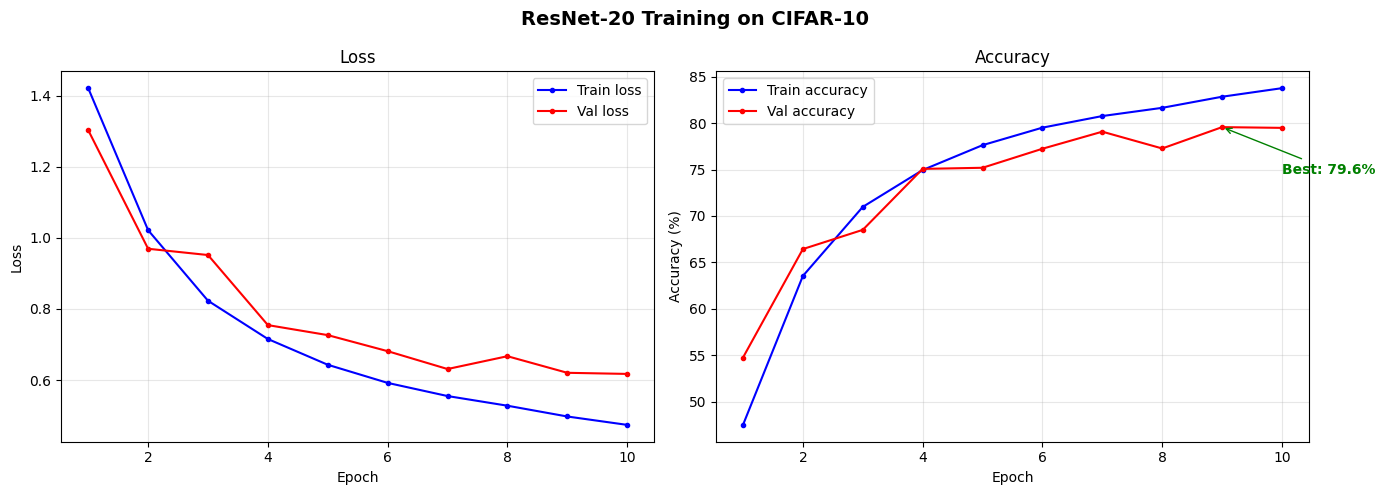

Train/val gap: 4.3% ✅ looks healthy


In [ ]:
epochs = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ResNet-20 Training on CIFAR-10', fontsize=14, fontweight='bold')

ax1.plot(epochs, history['train_loss'], 'b-o', markersize=3, label='Train loss')
ax1.plot(epochs, history['val_loss'],   'r-o', markersize=3, label='Val loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title('Loss')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(epochs, history['train_acc'], 'b-o', markersize=3, label='Train accuracy')
ax2.plot(epochs, history['val_acc'],   'r-o', markersize=3, label='Val accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Accuracy')
ax2.legend(); ax2.grid(True, alpha=0.3)

best_epoch = np.argmax(history['val_acc']) + 1
best_acc   = max(history['val_acc'])
ax2.annotate(f'Best: {best_acc:.1f}%',
             xy=(best_epoch, best_acc), xytext=(best_epoch+1, best_acc-5),
             arrowprops=dict(arrowstyle='->', color='green'),
             color='green', fontweight='bold')

plt.tight_layout(); plt.show()

gap = history['train_acc'][-1] - history['val_acc'][-1]
print(f'Train/val gap: {gap:.1f}%', end=' ')
print('⚠️ some overfitting' if gap > 10 else '✅ looks healthy')

/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128038 (\N{BIRD}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 129420 (\N{DEER}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128056 (\N{FROG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128052 (\N{HORSE FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1482318494.py:29: UserWarning: Glyph 128674 (\N{SHIP}) missing from font(s) DejaVu Sans.
  plt.tight_layout

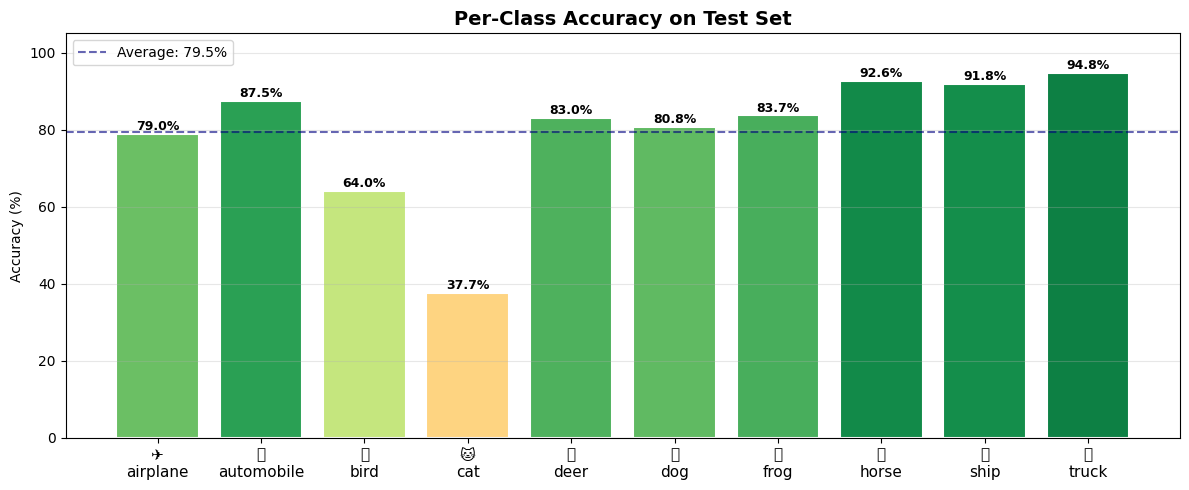


Per-class breakdown:
  ✈️ airplane    :  79.0%  ███████████████
  🚗 automobile  :  87.5%  █████████████████
  🐦 bird        :  64.0%  ████████████
  🐱 cat         :  37.7%  ███████
  🦌 deer        :  83.0%  ████████████████
  🐶 dog         :  80.8%  ████████████████
  🐸 frog        :  83.7%  ████████████████
  🐴 horse       :  92.6%  ██████████████████
  🚢 ship        :  91.8%  ██████████████████
  🚚 truck       :  94.8%  ██████████████████


In [ ]:
model.eval()
class_correct = [0] * 10
class_total   = [0] * 10

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        _, predicted = model(inputs).max(1)
        for label, pred in zip(labels, predicted):
            class_correct[label] += (label == pred).item()
            class_total[label]   += 1

class_acc = [100.0 * class_correct[i] / class_total[i] for i in range(10)]

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.RdYlGn([a / 100 for a in class_acc])
bars = ax.bar(range(10), class_acc, color=colors, edgecolor='white', linewidth=1.5)
ax.set_xticks(range(10))
ax.set_xticklabels([f'{CLASS_EMOJI[i]}\n{CLASS_NAMES[i]}' for i in range(10)], fontsize=11)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Per-Class Accuracy on Test Set', fontsize=14, fontweight='bold')
ax.set_ylim(0, 105)
ax.axhline(sum(class_acc)/10, color='navy', linestyle='--', alpha=0.6,
           label=f'Average: {sum(class_acc)/10:.1f}%')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            f'{acc:.1f}%', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.show()

print('\nPer-class breakdown:')
for i in range(10):
    bar = '█' * int(class_acc[i] / 5)
    print(f'  {CLASS_EMOJI[i]} {CLASS_NAMES[i]:12s}: {class_acc[i]:5.1f}%  {bar}')

/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 128674 (\N{SHIP}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 128666 (\N{DELIVERY TRUCK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 128052 (\N{HORSE FACE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 129420 (\N{DEER}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/1161291283.py:31: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) m

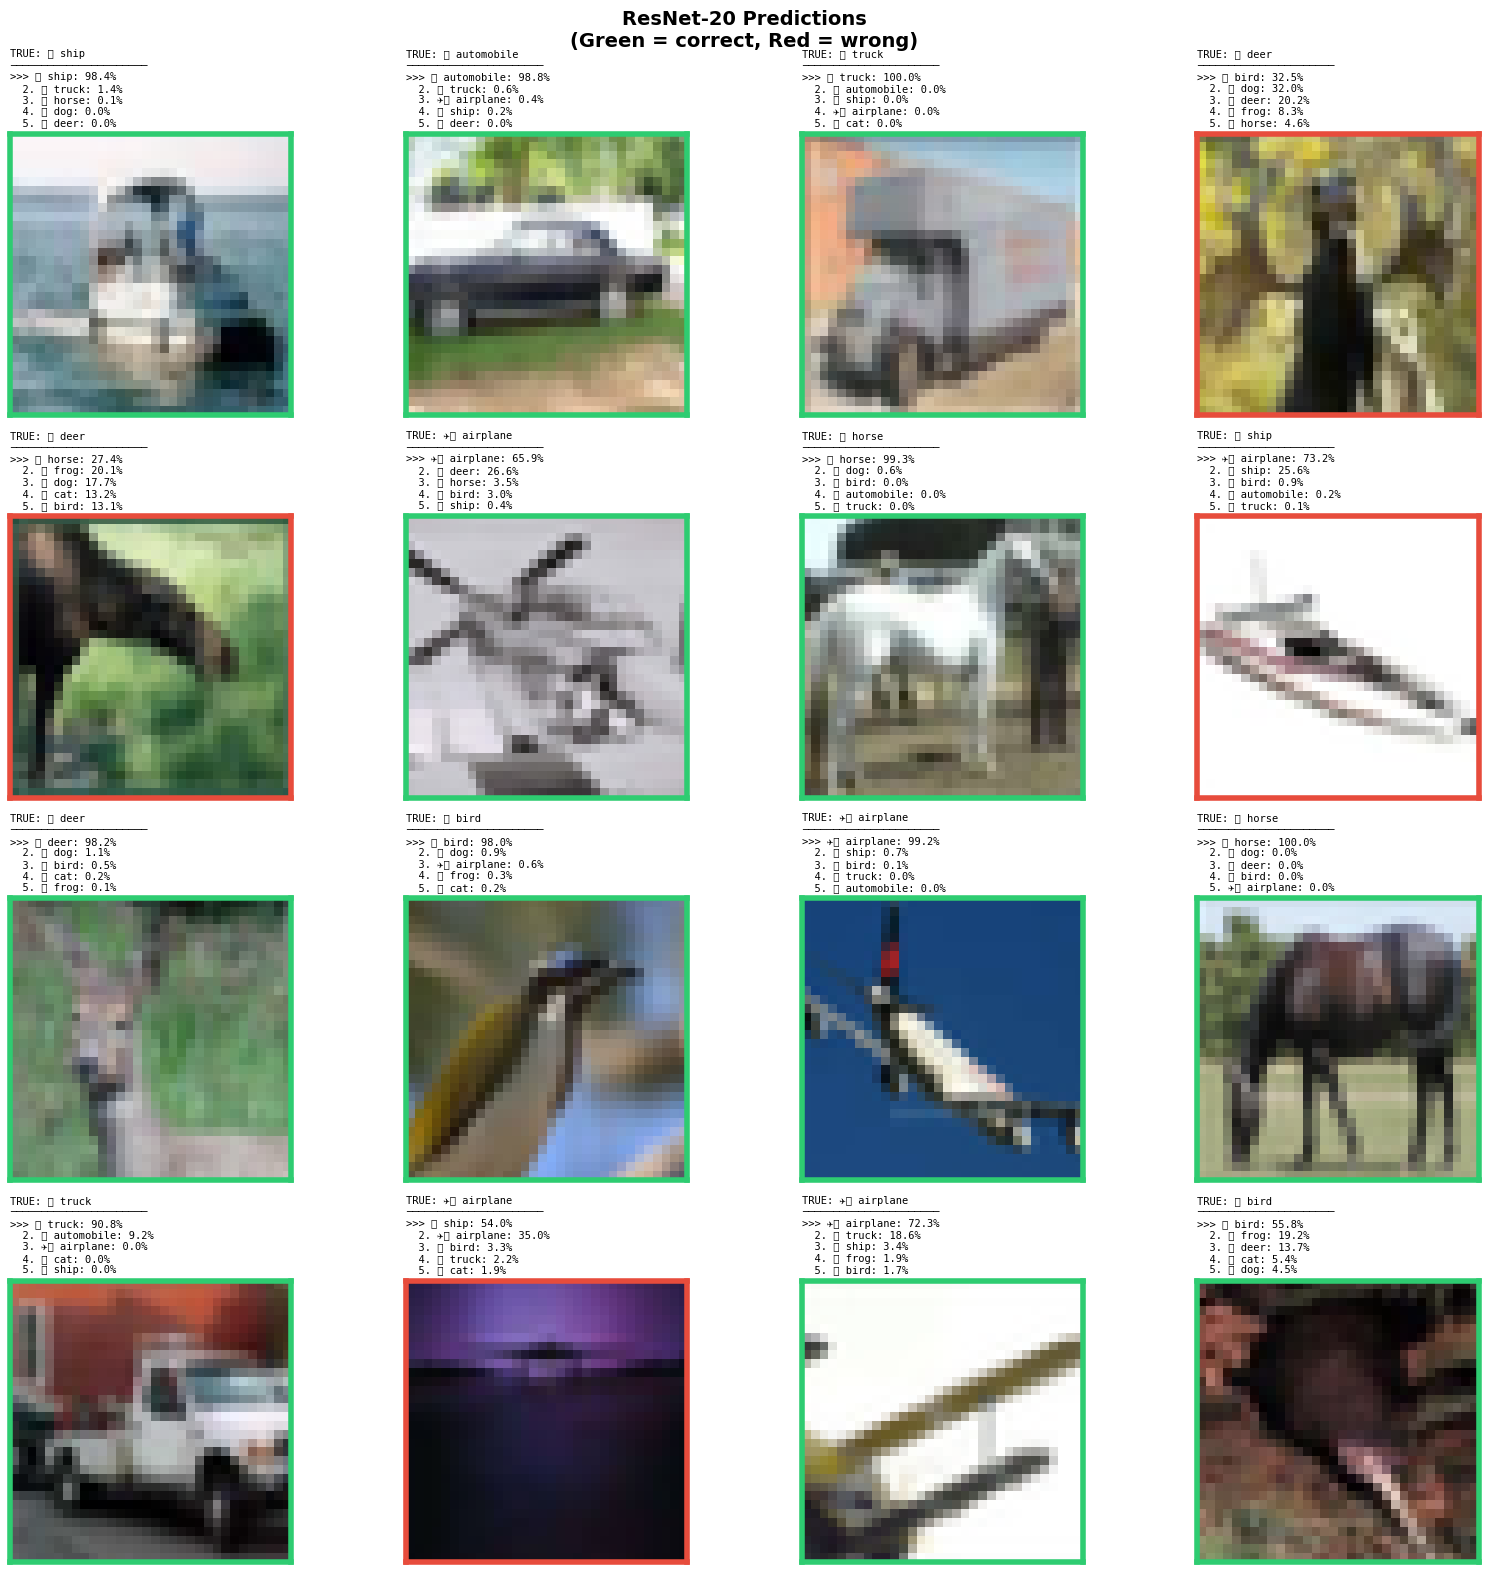

In [ ]:
model.eval()
indices = np.random.choice(len(test_dataset), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
fig.suptitle('ResNet-20 Predictions\n(Green = correct, Red = wrong)',
             fontsize=14, fontweight='bold')

with torch.no_grad():
    for ax, idx in zip(axes.flat, indices):
        img_tensor, true_label = test_dataset[idx]
        output = model(img_tensor.unsqueeze(0).to(device))
        probs  = torch.softmax(output, dim=1).squeeze().cpu().numpy()
        top5_idx  = probs.argsort()[::-1][:5]
        top5_prob = probs[top5_idx]
        correct   = (top5_idx[0] == true_label)

        ax.imshow(denormalize(img_tensor).permute(1, 2, 0))
        border_color = '#2ecc71' if correct else '#e74c3c'
        for spine in ax.spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(4)

        lines = [f'TRUE: {CLASS_EMOJI[true_label]} {CLASS_NAMES[true_label]}', '─'*22]
        for rank, (ci, prob) in enumerate(zip(top5_idx, top5_prob)):
            marker = '>>>' if rank == 0 else f'  {rank+1}.'
            lines.append(f'{marker} {CLASS_EMOJI[ci]} {CLASS_NAMES[ci]}: {prob*100:.1f}%')

        ax.set_title('\n'.join(lines), fontsize=7.5, loc='left', fontfamily='monospace')
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout(); plt.show()

/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128038 (\N{BIRD}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 129420 (\N{DEER}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128056 (\N{FROG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128052 (\N{HORSE FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1093/3084211233.py:28: UserWarning: Glyph 128674 (\N{SHIP}) missing from font(s) DejaVu Sans.
  plt.tight_layout

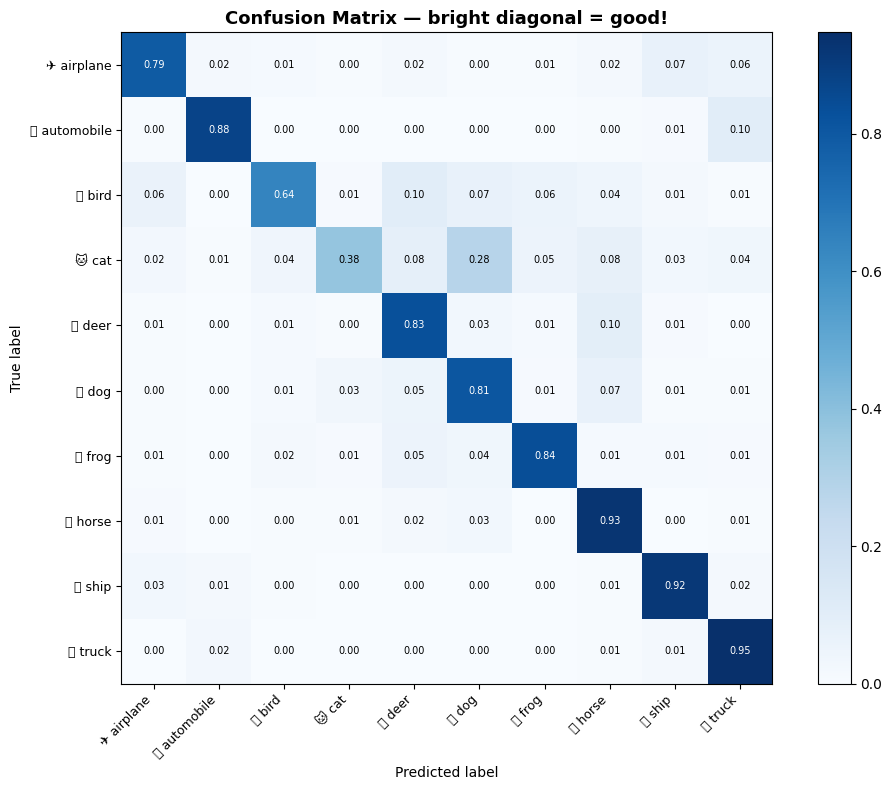


Top confusions:
  🐱 cat          mistaken for 🐶 dog          (281x)
  🚗 automobile   mistaken for 🚚 truck        (101x)
  🐦 bird         mistaken for 🦌 deer         (100x)
  🦌 deer         mistaken for 🐴 horse        (95x)
  🐱 cat          mistaken for 🦌 deer         (83x)


In [ ]:
from sklearn.metrics import confusion_matrix
import itertools

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        _, predicted = model(inputs.to(device)).max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm_norm, cmap='Blues')
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Confusion Matrix — bright diagonal = good!', fontsize=13, fontweight='bold')
tick_labels = [f'{CLASS_EMOJI[i]} {CLASS_NAMES[i]}' for i in range(10)]
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel('True label'); ax.set_xlabel('Predicted label')
thresh = cm_norm.max() / 2
for i, j in itertools.product(range(10), range(10)):
    ax.text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center', fontsize=7,
            color='white' if cm_norm[i,j] > thresh else 'black')
plt.tight_layout(); plt.show()

print('\nTop confusions:')
off_diag = [(cm[i,j], i, j) for i in range(10) for j in range(10) if i != j]
for count, true, pred in sorted(off_diag, reverse=True)[:5]:
    print(f'  {CLASS_EMOJI[true]} {CLASS_NAMES[true]:12s} mistaken for {CLASS_EMOJI[pred]} {CLASS_NAMES[pred]:12s} ({count}x)')

In [ ]:
# This cell lets you reflect on what residual connections actually bought you.
# ResNet-20 has fewer parameters than your Mini-AlexNet but should be more accurate
# purely because of the skip connections enabling better gradient flow.

alexnet_params = 1_000_000  # approximate from your earlier implementation
resnet_params  = sum(p.numel() for p in model.parameters() if p.requires_grad)
resnet_best    = max(history['val_acc'])

print('=' * 50)
print('Architecture Comparison')
print('=' * 50)
print(f'Mini-AlexNet  : ~{alexnet_params:,} params, ~78-82% accuracy')
print(f'ResNet-20     : ~{resnet_params:,} params, {resnet_best:.1f}% accuracy')
print()
print('Key architectural differences:')
print('  AlexNet : Large filters (11x11, 5x5), no skip connections')
print('  ResNet  : Small filters (3x3 only),   skip connections everywhere')
print()
print('The accuracy difference comes almost entirely from skip connections')
print('allowing gradients to flow cleanly through 20 layers vs 8.')

Architecture Comparison
Mini-AlexNet  : ~1,000,000 params, ~78-82% accuracy
ResNet-20     : ~272,474 params, 79.6% accuracy

Key architectural differences:
  AlexNet : Large filters (11x11, 5x5), no skip connections
  ResNet  : Small filters (3x3 only),   skip connections everywhere

The accuracy difference comes almost entirely from skip connections
allowing gradients to flow cleanly through 20 layers vs 8.
